In [1]:
import duckdb
con = duckdb.connect('../homecredit.duckdb')

con.execute("""
CREATE OR REPLACE TABLE prev AS
SELECT * FROM read_csv_auto('../data/previous_application.csv')
""")
con.execute("""
CREATE OR REPLACE TABLE inst AS
SELECT * FROM read_csv_auto('../data/installments_payments.csv')
""")

print(con.execute("SELECT COUNT(*) FROM prev").fetchone())
print(con.execute("SELECT COUNT(*) FROM inst").fetchone())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(1670214,)
(13605401,)


In [2]:
def q(sql):
    return con.execute(sql).df()

q("DESCRIBE prev")

,column_name,column_type,null,key,default,extra
0,SK_ID_PREV,BIGINT,YES,None,None,None
1,SK_ID_CURR,BIGINT,YES,None,None,None
2,NAME_CONTRACT_TYPE,VARCHAR,YES,None,None,None
3,AMT_ANNUITY,DOUBLE,YES,None,None,None
4,AMT_APPLICATION,DOUBLE,YES,None,None,None
5,AMT_CREDIT,DOUBLE,YES,None,None,None
6,AMT_DOWN_PAYMENT,DOUBLE,YES,None,None,None
7,AMT_GOODS_PRICE,DOUBLE,YES,None,None,None
8,WEEKDAY_APPR_PROCESS_START,VARCHAR,YES,None,None,None
9,HOUR_APPR_PROCESS_START,BIGINT,YES,None,None,None


In [3]:
q("DESCRIBE inst")

,column_name,column_type,null,key,default,extra
0,SK_ID_PREV,BIGINT,YES,None,None,None
1,SK_ID_CURR,BIGINT,YES,None,None,None
2,NUM_INSTALMENT_VERSION,DOUBLE,YES,None,None,None
3,NUM_INSTALMENT_NUMBER,BIGINT,YES,None,None,None
4,DAYS_INSTALMENT,DOUBLE,YES,None,None,None
5,DAYS_ENTRY_PAYMENT,DOUBLE,YES,None,None,None
6,AMT_INSTALMENT,DOUBLE,YES,None,None,None
7,AMT_PAYMENT,DOUBLE,YES,None,None,None


In [4]:
q("DESCRIBE inst")

,column_name,column_type,null,key,default,extra
0,SK_ID_PREV,BIGINT,YES,None,None,None
1,SK_ID_CURR,BIGINT,YES,None,None,None
2,NUM_INSTALMENT_VERSION,DOUBLE,YES,None,None,None
3,NUM_INSTALMENT_NUMBER,BIGINT,YES,None,None,None
4,DAYS_INSTALMENT,DOUBLE,YES,None,None,None
5,DAYS_ENTRY_PAYMENT,DOUBLE,YES,None,None,None
6,AMT_INSTALMENT,DOUBLE,YES,None,None,None
7,AMT_PAYMENT,DOUBLE,YES,None,None,None


In [5]:
q("""
SELECT NAME_CONTRACT_TYPE, COUNT(*) AS n
FROM prev GROUP BY 1 ORDER BY n DESC
""")

,NAME_CONTRACT_TYPE,n
0,Cash loans,747553
1,Consumer loans,729151
2,Revolving loans,193164
3,XNA,346


In [6]:
q("""
SELECT NAME_CONTRACT_STATUS, COUNT(*) AS n
FROM prev WHERE NAME_CONTRACT_TYPE = 'Consumer loans'
GROUP BY 1 ORDER BY n DESC
""")

,NAME_CONTRACT_STATUS,n
0,Approved,626470
1,Refused,75185
2,Unused offer,25937
3,Canceled,1559


In [7]:
q("""
SELECT NAME_GOODS_CATEGORY, COUNT(*) AS n
FROM prev WHERE NAME_CONTRACT_TYPE = 'Consumer loans'
GROUP BY 1 ORDER BY n DESC
""")

,NAME_GOODS_CATEGORY,n
0,Mobile,224686
1,Consumer Electronics,121237
2,Computers,105748
3,Audio/Video,99357
4,Furniture,53640
5,Photo / Cinema Equipment,25018
6,Construction Materials,24995
7,Clothing and Accessories,23554
8,XNA,10232
9,Auto Accessories,7381


In [8]:
q("""
SELECT NAME_CONTRACT_STATUS,
       COUNT(*) AS loans,
       SUM(CASE WHEN CNT_PAYMENT IS NULL THEN 1 ELSE 0 END) AS missing_term
FROM prev
WHERE NAME_CONTRACT_TYPE = 'Consumer loans'
GROUP BY 1
""")

,NAME_CONTRACT_STATUS,loans,missing_term
0,Unused offer,25937,25027.0
1,Refused,75185,11347.0
2,Canceled,1559,1341.0
3,Approved,626470,0.0


In [9]:
q("""
SELECT COUNT(*) AS total,
       SUM(CASE WHEN DAYS_ENTRY_PAYMENT IS NULL THEN 1 ELSE 0 END) AS no_payment_date
FROM inst
""")

,total,no_payment_date
0,13605401,2905.0


In [10]:
q("""
SELECT COUNT(*) AS total,
       SUM(CASE WHEN DAYS_ENTRY_PAYMENT IS NULL THEN 1 ELSE 0 END) AS no_payment_date
FROM inst
""")

,total,no_payment_date
0,13605401,2905.0


In [11]:
q("""
SELECT COUNT(*) AS total_rows,
       (SELECT COUNT(*) FROM (SELECT DISTINCT SK_ID_PREV, NUM_INSTALMENT_NUMBER, NUM_INSTALMENT_VERSION FROM inst)) AS distinct_with_version,
       (SELECT COUNT(*) FROM (SELECT DISTINCT SK_ID_PREV, NUM_INSTALMENT_NUMBER FROM inst)) AS distinct_without_version
FROM inst
""")

,total_rows,distinct_with_version,distinct_without_version
0,13605401,12951918,12861994


In [12]:
q("""
SELECT NAME_CONTRACT_STATUS,
       COUNT(*) AS loans,
       SUM(CASE WHEN CNT_PAYMENT IS NULL THEN 1 ELSE 0 END) AS missing_term
FROM prev
WHERE NAME_CONTRACT_TYPE = 'Consumer loans'
GROUP BY 1
""")

,NAME_CONTRACT_STATUS,loans,missing_term
0,Unused offer,25937,25027.0
1,Approved,626470,0.0
2,Canceled,1559,1341.0
3,Refused,75185,11347.0


In [13]:
q("""
SELECT COUNT(*) AS total,
       SUM(CASE WHEN DAYS_ENTRY_PAYMENT IS NULL THEN 1 ELSE 0 END) AS no_payment_date
FROM inst
""")

,total,no_payment_date
0,13605401,2905.0


In [14]:
q("""
SELECT COUNT(*) AS total_rows,
       (SELECT COUNT(*) FROM (SELECT DISTINCT SK_ID_PREV, NUM_INSTALMENT_NUMBER, NUM_INSTALMENT_VERSION FROM inst)) AS distinct_with_version,
       (SELECT COUNT(*) FROM (SELECT DISTINCT SK_ID_PREV, NUM_INSTALMENT_NUMBER FROM inst)) AS distinct_without_version
FROM inst
""")

,total_rows,distinct_with_version,distinct_without_version
0,13605401,12951918,12861994


In [15]:
con.execute("""
CREATE OR REPLACE VIEW apps AS
SELECT SK_ID_PREV,
       NAME_CONTRACT_STATUS AS status,
       NAME_GOODS_CATEGORY AS category,
       CHANNEL_TYPE AS channel,
       CNT_PAYMENT AS term,
       AMT_CREDIT AS loan_amount
FROM prev
WHERE NAME_CONTRACT_TYPE = 'Consumer loans'
""")

con.execute("""
CREATE OR REPLACE VIEW approved_loans AS
SELECT * FROM apps WHERE status = 'Approved'
""")

q("SELECT (SELECT COUNT(*) FROM apps) AS apps, (SELECT COUNT(*) FROM approved_loans) AS approved")

,apps,approved
0,729151,626470


In [16]:
con.execute("""
CREATE OR REPLACE TABLE inst_clean AS
SELECT *
FROM inst
QUALIFY ROW_NUMBER() OVER (
  PARTITION BY SK_ID_PREV, NUM_INSTALMENT_NUMBER
  ORDER BY NUM_INSTALMENT_VERSION DESC, DAYS_ENTRY_PAYMENT DESC NULLS LAST
) = 1
""")

q("SELECT COUNT(*) AS n FROM inst_clean")

,n
0,12861994


In [17]:
con.execute("""
CREATE OR REPLACE TABLE installments AS
SELECT i.SK_ID_PREV,
       l.term,
       l.category,
       i.NUM_INSTALMENT_NUMBER AS inst_no,
       (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) AS days_late,
       CASE WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) > 0 THEN 1 ELSE 0 END AS is_late,
       CASE
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 0 THEN '1 On time or early'
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 7 THEN '2 1-7 days late'
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 30 THEN '3 8-30 days late'
         ELSE '4 31+ days late'
       END AS lateness_bucket
FROM inst_clean i
JOIN approved_loans l USING (SK_ID_PREV)
WHERE i.DAYS_ENTRY_PAYMENT IS NOT NULL
""")

In [18]:
q("""
SELECT COUNT(*) AS installments,
       COUNT(DISTINCT SK_ID_PREV) AS loans,
       MIN(days_late) AS min_days_late,
       MAX(days_late) AS max_days_late,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
""")


,installments,loans,min_days_late,max_days_late,pct_late
0,5258137,607983,-1600.0,2524.0,9.0


In [19]:
q("""
SELECT COUNT(*) AS installments,
       SUM(CASE WHEN days_late > 365 THEN 1 ELSE 0 END) AS over_1yr_late,
       SUM(CASE WHEN days_late < -365 THEN 1 ELSE 0 END) AS over_1yr_early
FROM installments
""")

,installments,over_1yr_late,over_1yr_early
0,5258137,2032.0,184.0


In [20]:
q("""
SELECT COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late,
       ROUND(100.0 * AVG(CASE WHEN days_late > 30 THEN 1 ELSE 0 END), 1) AS pct_over_30_days,
       MEDIAN(CASE WHEN is_late = 1 THEN days_late END) AS median_days_late_when_late
FROM installments
""")

,installments,pct_late,pct_over_30_days,median_days_late_when_late
0,5258137,9.0,0.4,5.0


In [21]:
q("""
SELECT lateness_bucket,
       COUNT(*) AS installments,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM installments
GROUP BY 1 ORDER BY 1
""")

,lateness_bucket,installments,pct
0,1 On time or early,4784197,91.0
1,2 1-7 days late,305088,5.8
2,3 8-30 days late,149658,2.8
3,4 31+ days late,19194,0.4


In [22]:
q("""
SELECT term,
       COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
WHERE term IS NOT NULL
GROUP BY 1
HAVING COUNT(*) >= 1000
ORDER BY 1
""")

,term,installments,pct_late
0,3.0,2714,4.3
1,4.0,88776,6.6
2,5.0,16700,7.5
3,6.0,752688,7.2
4,7.0,8479,9.7
5,8.0,191020,10.0
6,9.0,9055,11.7
7,10.0,1063365,9.0
8,11.0,5761,12.3
9,12.0,1778062,9.4


In [23]:
q("""
SELECT category,
       COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
GROUP BY 1
HAVING COUNT(*) >= 5000
ORDER BY pct_late DESC
""")

,category,installments,pct_late
0,XNA,10610,15.6
1,Other,20707,12.9
2,Mobile,1332111,10.3
3,Photo / Cinema Equipment,177370,9.8
4,Office Appliances,16823,9.8
5,Computers,822440,9.1
6,Vehicles,28119,9.1
7,Audio/Video,842350,9.0
8,Consumer Electronics,1018034,8.8
9,Sport and Leisure,20726,7.9


In [24]:
q("""
SELECT LEAST(inst_no, 12) AS inst_no_capped,
       COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
GROUP BY 1 ORDER BY 1
""")

,inst_no_capped,installments,pct_late
0,1,607983,3.4
1,2,592605,4.5
2,3,577230,5.7
3,4,555111,7.0
4,5,498953,8.5
5,6,457761,9.8
6,7,347542,10.3
7,8,324824,11.7
8,9,287611,12.6
9,10,259046,14.1


In [25]:
q("""
SELECT inst_no,
       COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
WHERE term = 12
GROUP BY 1 ORDER BY 1
""")

,inst_no,installments,pct_late
0,1,192848,3.3
1,2,188007,4.2
2,3,183189,5.4
3,4,176522,6.7
4,5,163589,8.1
5,6,155498,9.1
6,7,143942,10.7
7,8,135655,12.1
8,9,126891,13.5
9,10,117450,15.1


In [26]:
q("""
SELECT inst_no,
       COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
WHERE term = 12
GROUP BY 1 ORDER BY 1
""")

,inst_no,installments,pct_late
0,1,192848,3.3
1,2,188007,4.2
2,3,183189,5.4
3,4,176522,6.7
4,5,163589,8.1
5,6,155498,9.1
6,7,143942,10.7
7,8,135655,12.1
8,9,126891,13.5
9,10,117450,15.1


In [27]:
views_sql = '''-- 01_views.sql
-- Consumer loan applications (all statuses) and approved loans only
CREATE OR REPLACE VIEW apps AS
SELECT SK_ID_PREV, NAME_CONTRACT_STATUS AS status, NAME_GOODS_CATEGORY AS category,
       CHANNEL_TYPE AS channel, CNT_PAYMENT AS term, AMT_CREDIT AS loan_amount
FROM prev
WHERE NAME_CONTRACT_TYPE = 'Consumer loans';

CREATE OR REPLACE VIEW approved_loans AS
SELECT * FROM apps WHERE status = 'Approved';

-- One row per loan and installment number (latest schedule version, latest payment)
CREATE OR REPLACE TABLE inst_clean AS
SELECT * FROM inst
QUALIFY ROW_NUMBER() OVER (
  PARTITION BY SK_ID_PREV, NUM_INSTALMENT_NUMBER
  ORDER BY NUM_INSTALMENT_VERSION DESC, DAYS_ENTRY_PAYMENT DESC NULLS LAST
) = 1;

-- Installment-level table with days late and lateness buckets
CREATE OR REPLACE TABLE installments AS
SELECT i.SK_ID_PREV, l.term, l.category, i.NUM_INSTALMENT_NUMBER AS inst_no,
       (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) AS days_late,
       CASE WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) > 0 THEN 1 ELSE 0 END AS is_late,
       CASE
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 0 THEN '1 On time or early'
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 7 THEN '2 1-7 days late'
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 30 THEN '3 8-30 days late'
         ELSE '4 31+ days late'
       END AS lateness_bucket
FROM inst_clean i
JOIN approved_loans l USING (SK_ID_PREV)
WHERE i.DAYS_ENTRY_PAYMENT IS NOT NULL;
'''

metrics_sql = '''-- 02_metrics.sql

-- Q1: overall lateness
SELECT COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late,
       ROUND(100.0 * AVG(CASE WHEN days_late > 30 THEN 1 ELSE 0 END), 1) AS pct_over_30_days,
       MEDIAN(CASE WHEN is_late = 1 THEN days_late END) AS median_days_late_when_late
FROM installments;

-- Q1b: distribution of lateness
SELECT lateness_bucket, COUNT(*) AS installments,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM installments GROUP BY 1 ORDER BY 1;

-- Q2: late rate by loan term (groups under 1000 installments excluded)
SELECT term, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments WHERE term IS NOT NULL
GROUP BY 1 HAVING COUNT(*) >= 1000 ORDER BY 1;

-- Q3: late rate by goods category (groups under 5000 installments excluded)
SELECT category, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
GROUP BY 1 HAVING COUNT(*) >= 5000 ORDER BY pct_late DESC;

-- Q4: late rate by installment number (12 = 12 or later)
SELECT LEAST(inst_no, 12) AS inst_no_capped, COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments GROUP BY 1 ORDER BY 1;

-- Q4 check: same pattern within 12-month loans only
SELECT inst_no, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments WHERE term = 12 GROUP BY 1 ORDER BY 1;
'''

open('../sql/01_views.sql', 'w').write(views_sql)
open('../sql/02_metrics.sql', 'w').write(metrics_sql)
print("saved")

saved


In [28]:
readme_add = '''

## Problem statement
Which loan terms, product categories and installment stages are linked to late repayment on point-of-sale installment loans, and what would a product or risk team change in reminders or approvals?

## Data
Home Credit Default Risk (Kaggle): previous_application.csv (1,670,214 applications) and installments_payments.csv (13,605,401 rows). Data files are not included in this repository.

## Definitions
- Days late: actual payment day minus due day. Late means days late greater than 0.
- Only approved consumer loans with a recorded payment date are analyzed (607,983 loans, 5,258,137 installments).
- Where an installment has several payment rows or schedule versions, the latest version and latest payment date are used.

## Limitations
- This is point-of-sale installment lending, used as the closest public equivalent to buy-now-pay-later. It is not BNPL data.
- Only approved loans have repayment history, so results describe approved customers only.
- 2,905 installments had no payment date and were excluded.
- Dates are relative days, so there is no calendar or seasonal analysis.
- Results show associations, not causes.
'''
open('../README.md', 'a').write(readme_add)
print("README updated")

README updated


In [29]:
import os
print(os.listdir('../sql'))
print(open('../README.md').read()[:400])

['01_views.sql', '02_metrics.sql']
# Repayment behavior on point-of-sale installment loans 


## Problem statement
Which loan terms, product categories and installment stages are linked to late repayment on point-of-sale installment loans, and what would a product or risk team change in reminders or approvals?

## Data
Home Credit Default Risk (Kaggle): previous_application.csv (1,670,214 applications) and installments_payments.csv


In [30]:
q("""
SELECT COUNT(*) AS installments,
       SUM(CASE WHEN days_late > 365 THEN 1 ELSE 0 END) AS over_1yr_late,
       SUM(CASE WHEN days_late < -365 THEN 1 ELSE 0 END) AS over_1yr_early
FROM installments
""")

,installments,over_1yr_late,over_1yr_early
0,5258137,2032.0,184.0


In [31]:
q("""
SELECT inst_no,
       COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
WHERE term = 12
GROUP BY 1 ORDER BY 1
""")

,inst_no,installments,pct_late
0,1,192848,3.3
1,2,188007,4.2
2,3,183189,5.4
3,4,176522,6.7
4,5,163589,8.1
5,6,155498,9.1
6,7,143942,10.7
7,8,135655,12.1
8,9,126891,13.5
9,10,117450,15.1


In [32]:
q("""
SELECT COUNT(*) AS rows_beyond_term,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
WHERE inst_no > term
""")

,rows_beyond_term,pct_late
0,10653,90.2


In [33]:
con.execute("""
CREATE OR REPLACE TABLE installments AS
SELECT i.SK_ID_PREV, l.term, l.category, i.NUM_INSTALMENT_NUMBER AS inst_no,
       (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) AS days_late,
       CASE WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) > 0 THEN 1 ELSE 0 END AS is_late,
       CASE
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 0 THEN '1 On time or early'
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 7 THEN '2 1-7 days late'
         WHEN (i.DAYS_ENTRY_PAYMENT - i.DAYS_INSTALMENT) <= 30 THEN '3 8-30 days late'
         ELSE '4 31+ days late'
       END AS lateness_bucket
FROM inst_clean i
JOIN approved_loans l USING (SK_ID_PREV)
WHERE i.DAYS_ENTRY_PAYMENT IS NOT NULL
  AND i.NUM_INSTALMENT_NUMBER <= l.term
""")
q("SELECT COUNT(*) AS installments, COUNT(DISTINCT SK_ID_PREV) AS loans, ROUND(100.0 * AVG(is_late), 1) AS pct_late FROM installments")

,installments,loans,pct_late
0,5247484,607983,8.8


In [34]:
s = open('../sql/01_views.sql').read()
s = s.replace(
  "WHERE i.DAYS_ENTRY_PAYMENT IS NOT NULL;",
  "WHERE i.DAYS_ENTRY_PAYMENT IS NOT NULL\n  AND i.NUM_INSTALMENT_NUMBER <= l.term;  -- drop rows numbered beyond the loan term (extra or special payments)"
)
open('../sql/01_views.sql', 'w').write(s)
print('NUM_INSTALMENT_NUMBER <= l.term' in s)

True


In [35]:
from IPython.display import display
for stmt in open('../sql/02_metrics.sql').read().split(';'):
    if 'SELECT' in stmt:
        display(q(stmt))

,installments,pct_late,pct_over_30_days,median_days_late_when_late
0,5247484,8.8,0.3,4.0


,lateness_bucket,installments,pct
0,1 On time or early,4783148,91.2
1,2 1-7 days late,301751,5.8
2,3 8-30 days late,146578,2.8
3,4 31+ days late,16007,0.3


,term,installments,pct_late
0,3.0,2706,4.0
1,4.0,88483,6.3
2,5.0,16663,7.3
3,6.0,750964,7.0
4,7.0,8451,9.4
5,8.0,190501,9.8
6,9.0,9020,11.5
7,10.0,1061131,8.8
8,11.0,5747,12.2
9,12.0,1774488,9.2


,category,installments,pct_late
0,XNA,10585,15.5
1,Other,20603,12.5
2,Mobile,1328736,10.1
3,Photo / Cinema Equipment,177019,9.7
4,Office Appliances,16794,9.7
5,Computers,820668,8.9
6,Vehicles,28053,8.9
7,Audio/Video,840889,8.8
8,Consumer Electronics,1016209,8.6
9,Sport and Leisure,20674,7.7


,inst_no_capped,installments,pct_late
0,1,607983,3.4
1,2,592605,4.5
2,3,577230,5.7
3,4,555111,7.0
4,5,498952,8.5
5,6,457760,9.8
6,7,347490,10.3
7,8,324824,11.7
8,9,287607,12.6
9,10,259046,14.1


,inst_no,installments,pct_late
0,1,192848,3.3
1,2,188007,4.2
2,3,183189,5.4
3,4,176522,6.7
4,5,163589,8.1
5,6,155498,9.1
6,7,143942,10.7
7,8,135655,12.1
8,9,126891,13.5
9,10,117450,15.1


In [36]:
print("Rows numbered beyond the loan term (should be 0):")
print(q("SELECT COUNT(*) AS n FROM installments WHERE inst_no > term").to_string(index=False))

print("\nQ1 overall:")
print(q("""
SELECT COUNT(*) AS installments,
       COUNT(DISTINCT SK_ID_PREV) AS loans,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late,
       ROUND(100.0 * AVG(CASE WHEN days_late > 30 THEN 1 ELSE 0 END), 1) AS pct_over_30_days,
       MEDIAN(CASE WHEN is_late = 1 THEN days_late END) AS median_days_late_when_late
FROM installments
""").to_string(index=False))

print("\nLateness buckets:")
print(q("""
SELECT lateness_bucket, COUNT(*) AS installments,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM installments GROUP BY 1 ORDER BY 1
""").to_string(index=False))

print("\nQ4 late rate by installment number:")
print(q("""
SELECT LEAST(inst_no, 12) AS inst_no_capped, COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments GROUP BY 1 ORDER BY 1
""").to_string(index=False))

Rows numbered beyond the loan term (should be 0):
 n
 0

Q1 overall:
 installments  loans  pct_late  pct_over_30_days  median_days_late_when_late
      5247484 607983       8.8               0.3                         4.0

Lateness buckets:
   lateness_bucket  installments  pct
1 On time or early       4783148 91.2
   2 1-7 days late        301751  5.8
  3 8-30 days late        146578  2.8
   4 31+ days late         16007  0.3

Q4 late rate by installment number:
 inst_no_capped  installments  pct_late
              1        607983       3.4
              2        592605       4.5
              3        577230       5.7
              4        555111       7.0
              5        498952       8.5
              6        457760       9.8
              7        347490      10.3
              8        324824      11.7
              9        287607      12.6
             10        259046      14.1
             11        171130      14.7
             12        567746      15.1


In [37]:
print("Q2 late rate by term:")
print(q("""
SELECT term, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments WHERE term IS NOT NULL
GROUP BY 1 HAVING COUNT(*) >= 1000 ORDER BY 1
""").to_string(index=False))

print("\nQ3 late rate by category:")
print(q("""
SELECT category, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
GROUP BY 1 HAVING COUNT(*) >= 5000 ORDER BY pct_late DESC
""").to_string(index=False))

Q2 late rate by term:
 term  installments  pct_late
  3.0          2706       4.0
  4.0         88483       6.3
  5.0         16663       7.3
  6.0        750964       7.0
  7.0          8451       9.4
  8.0        190501       9.8
  9.0          9020      11.5
 10.0       1061131       8.8
 11.0          5747      12.2
 12.0       1774488       9.2
 14.0         81287      11.8
 15.0          1480      12.2
 16.0         57046      12.9
 18.0        271947       9.2
 20.0          9924       9.5
 24.0        834878       9.1
 30.0         12021       8.0
 36.0         61889       7.5
 60.0          4297      20.0
 72.0          1769      13.5

Q3 late rate by category:
                category  installments  pct_late
                     XNA         10585      15.5
                   Other         20603      12.5
                  Mobile       1328736      10.1
Photo / Cinema Equipment        177019       9.7
       Office Appliances         16794       9.7
               Computers   

In [38]:
print(q("""
SELECT LEAST(inst_no, 12) AS inst_no_capped, COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments GROUP BY 1 ORDER BY 1 DESC LIMIT 2
""").to_string(index=False))

 inst_no_capped  installments  pct_late
             12        567746      15.1
             11        171130      14.7


In [39]:
open('../README.md', 'a').write('''
- Installment rows numbered beyond the loan term (10,653 rows, about 0.2%, likely extra or special payments) were excluded.
- Very small groups were excluded from category and term results (under 5,000 and 1,000 installments respectively).
''')
print("added")

added


In [40]:
notes = '''# Project notes: final numbers (after fixes)

## Data preparation
- previous_application: 1,670,214 applications; consumer loans 729,151
- Consumer loan statuses: Approved 626,470, Refused 75,185, Unused offer 25,937, Canceled 1,559
- Loan term missing: 0 of 626,470 approved loans; most unused offers (25,027), canceled (1,341) and many refused (11,347) have no term
- installments_payments: 13,605,401 rows; 2,905 had no payment date (excluded)
- Duplicates: 12,861,994 distinct loan and installment-number pairs; kept the latest schedule version and latest payment
- Installment rows numbered beyond the loan term removed: 10,653 (about 0.2%)
- Analysis set: 5,247,484 installments across 607,983 approved consumer loans
- Extremes (measured before the beyond-term filter): 2,032 installments more than 1 year late, 184 more than 1 year early

## Q1: overall lateness
- 8.8% of installments paid late
- On time or early 91.2%; 1-7 days late 5.8%; 8-30 days late 2.8%; 31+ days late 0.3%
- Median late payment: 4 days late

## Q2: loan term
- Large groups are close together: 10 months 8.8%, 12 months 9.2%, 18 months 9.2%, 24 months 9.1%
- 6 months lower at 7.0%; 36 months 7.5%
- 14 months 11.8%, 16 months 12.9%
- 60 months 20.0% (4,297 installments) and 72 months 13.5% (1,769): small groups, weak evidence
- Summary: term alone is a weak signal among the largest groups

## Q3: goods category
- Highest among large categories: Mobile 10.1% (1,328,736 installments)
- Lowest: Jewelry 5.1%, Tourism 5.5%, Medical Supplies 5.7%
- XNA (15.5%) and Other (12.5%) are unclear categories, kept out of headline findings

## Q4: installment number
- Late rate rises from 3.4% at installment 1 to 14.7% at installment 11 and 15.1% at 12 or later
- Within 12-month loans only: 3.3% at installment 1 to 18.4% at installment 12
- The pattern holds among loans of the same length

## Caveats
- Only approved loans have repayment history (selection bias)
- Point-of-sale installment lending, not BNPL
- Results show associations, not causes
'''
open('../docs/notes.md', 'w', encoding='utf-8').write(notes)
print("notes saved")

notes saved


In [1]:
import duckdb
con = duckdb.connect('../homecredit.duckdb')
def q(sql):
    return con.execute(sql).df()

q("SELECT COUNT(*) AS n FROM installments")

,n
0,5247484


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs('../docs', exist_ok=True)
os.makedirs('../summary', exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (9, 5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.axisbelow': True,
    'font.size': 11,
})
PURPLE = '#7F77DD'; TEAL = '#1D9E75'; CORAL = '#D85A30'; GRAY = '#B4B2A9'

overall = q("SELECT ROUND(100.0 * AVG(is_late), 1) AS p FROM installments")['p'][0]
print("overall late rate:", overall)

overall late rate: 8.8


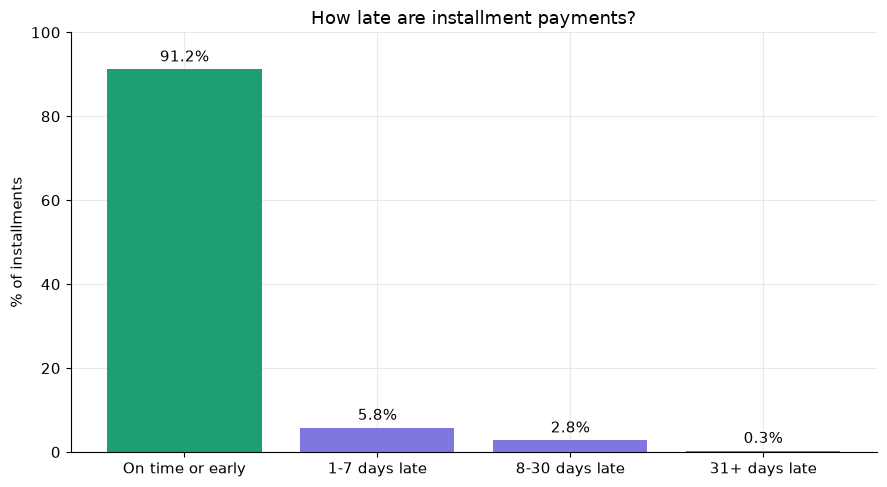

In [3]:
buckets = q("""
SELECT lateness_bucket, COUNT(*) AS installments,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM installments GROUP BY 1 ORDER BY 1
""")
buckets['label'] = buckets['lateness_bucket'].str[2:]

fig, ax = plt.subplots()
bars = ax.bar(buckets['label'], buckets['pct'], color=[TEAL, PURPLE, PURPLE, CORAL])
ax.bar_label(bars, labels=[f"{v}%" for v in buckets['pct']], padding=3)
ax.set_title('How late are installment payments?')
ax.set_ylabel('% of installments')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig('../docs/q1_lateness_distribution.png', dpi=150)
plt.show()

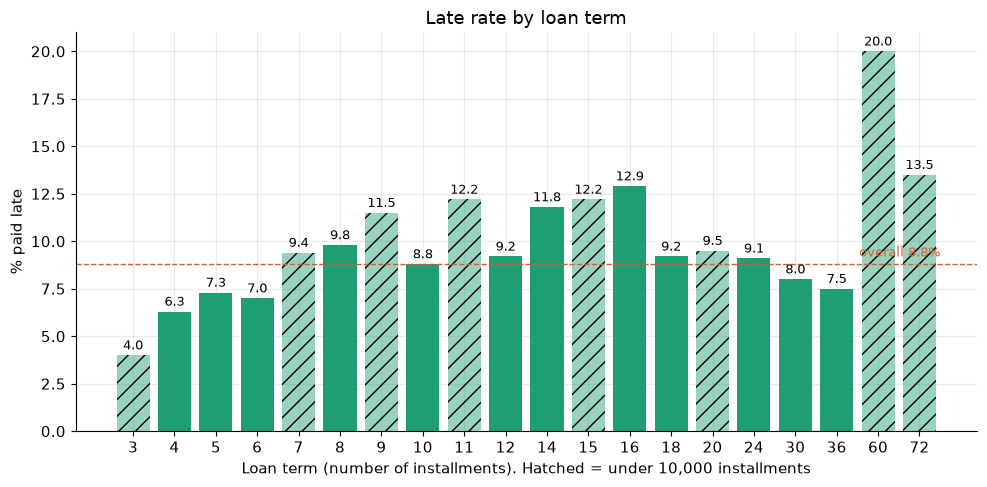

In [4]:
by_term = q("""
SELECT term, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments WHERE term IS NOT NULL
GROUP BY 1 HAVING COUNT(*) >= 1000 ORDER BY 1
""")
by_term['term'] = by_term['term'].astype(int)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(by_term['term'].astype(str), by_term['pct_late'], color=TEAL)
for bar, n in zip(bars, by_term['installments']):
    if n < 10000:
        bar.set_alpha(0.45)
        bar.set_hatch('//')
ax.bar_label(bars, labels=[f"{v}" for v in by_term['pct_late']], padding=2, fontsize=9)
ax.axhline(overall, color=CORAL, linestyle='--', linewidth=1)
ax.text(len(by_term) - 0.5, overall + 0.4, f'overall {overall}%', color=CORAL, ha='right', fontsize=9)
ax.set_title('Late rate by loan term')
ax.set_xlabel('Loan term (number of installments). Hatched = under 10,000 installments')
ax.set_ylabel('% paid late')
plt.tight_layout()
plt.savefig('../docs/q2_late_by_term.png', dpi=150)
plt.show()

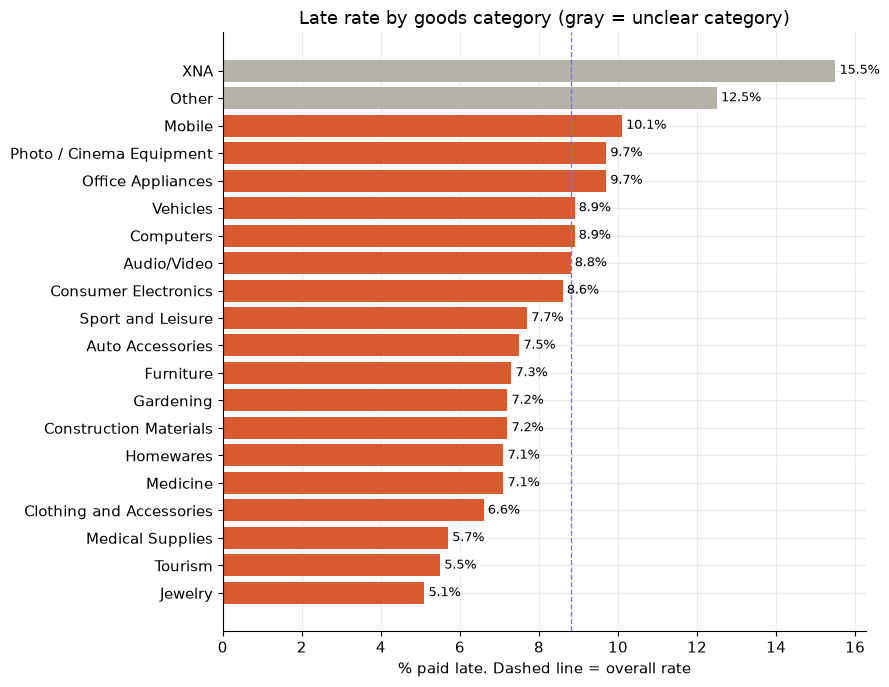

In [5]:
by_cat = q("""
SELECT category, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments
GROUP BY 1 HAVING COUNT(*) >= 5000 ORDER BY pct_late
""")
colors = [GRAY if c in ('XNA', 'Other') else CORAL for c in by_cat['category']]

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(by_cat['category'], by_cat['pct_late'], color=colors)
ax.bar_label(bars, labels=[f"{v}%" for v in by_cat['pct_late']], padding=3, fontsize=9)
ax.axvline(overall, color=PURPLE, linestyle='--', linewidth=1)
ax.set_title('Late rate by goods category (gray = unclear category)')
ax.set_xlabel('% paid late. Dashed line = overall rate')
plt.tight_layout()
plt.savefig('../docs/q3_late_by_category.png', dpi=150)
plt.show()

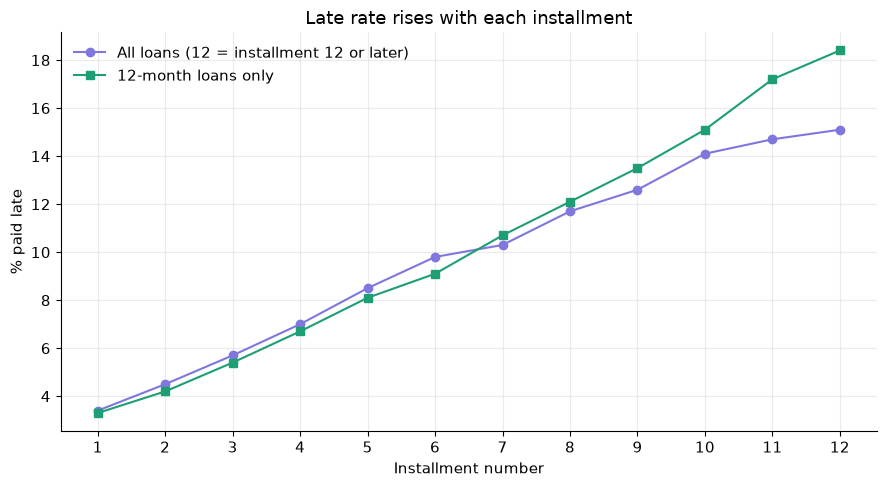

In [6]:
by_no = q("""
SELECT LEAST(inst_no, 12) AS inst_no_capped, COUNT(*) AS installments,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments GROUP BY 1 ORDER BY 1
""")
by_no12 = q("""
SELECT inst_no, COUNT(*) AS installments, ROUND(100.0 * AVG(is_late), 1) AS pct_late
FROM installments WHERE term = 12 GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.plot(by_no['inst_no_capped'], by_no['pct_late'], marker='o', color=PURPLE,
        label='All loans (12 = installment 12 or later)')
ax.plot(by_no12['inst_no'], by_no12['pct_late'], marker='s', color=TEAL,
        label='12-month loans only')
ax.set_xticks(range(1, 13))
ax.set_title('Late rate rises with each installment')
ax.set_xlabel('Installment number')
ax.set_ylabel('% paid late')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('../docs/q4_late_by_installment_no.png', dpi=150)
plt.show()

In [7]:
kpis = q("""
SELECT COUNT(*) AS installments, COUNT(DISTINCT SK_ID_PREV) AS loans,
       ROUND(100.0 * AVG(is_late), 1) AS pct_late,
       ROUND(100.0 * AVG(CASE WHEN days_late > 30 THEN 1 ELSE 0 END), 1) AS pct_over_30_days,
       MEDIAN(CASE WHEN is_late = 1 THEN days_late END) AS median_days_late_when_late
FROM installments
""")
kpis.to_csv('../summary/kpis.csv', index=False)
buckets[['label', 'installments', 'pct']].to_csv('../summary/lateness_buckets.csv', index=False)
by_term.to_csv('../summary/late_by_term.csv', index=False)
by_cat.sort_values('pct_late', ascending=False).to_csv('../summary/late_by_category.csv', index=False)
by_no.to_csv('../summary/late_by_installment_no.csv', index=False)
by_no12.to_csv('../summary/late_by_installment_no_12m.csv', index=False)
print(os.listdir('../summary'))
print(os.listdir('../docs'))

['kpis.csv', 'lateness_buckets.csv', 'late_by_category.csv', 'late_by_installment_no.csv', 'late_by_installment_no_12m.csv', 'late_by_term.csv']
['notes.md', 'q1_lateness_distribution.png', 'q2_late_by_term.png', 'q3_late_by_category.png', 'q4_late_by_installment_no.png']
